# Game preservation token economics

Option B · Python calculations and simulations for one offline PC game

How much can each primary licence sale contribute to preservation, and how long can the archive keep serving players if sales dry up? The model tracks one licence per token, funds an independent backup host, and sets aside free claims for eligible past buyers.

**Where the numbers came from.** The project decisions supplied the rules for
licences, claims, royalties and the independent backup. Every numerical input
is a hypothetical value chosen to demonstrate the model. Section 2 explains
why the saved run uses these values.

## Saved run at a glance

- At **€12.00** per paid licence, the rights holder receives **€3.60** and the archive retains **€7.50** after checkout and initial delivery.
- With zero paid sales from launch, the reserve covers **24 full months**. Month 25 is **€48.00 short**, including the effect of serving the budgeted free claims.
- Funding all five years from sales alone would take **1,167 paid licences** against a capacity of **1,000**. Even a sellout leaves **€1,248.00** to fund.

Edit the assumptions in Section 2 and run all cells to recalculate the tables, figures and result notes. This opening summary records the saved run.

The scope follows **Assessments2026.pdf**, Option B, pages 2–3, and **Game Preservation Project Decisions.docx**. DOOM (1993) is the motivating example. The agreed pilot uses Freedoom Phase 1 with Crispy Doom.

## 1. Set up the notebook

The model uses decimal arithmetic and rounds at the sale level because the publisher and payment processor each receive amounts in cents. Tables and charts let us inspect the same calculation at different levels of detail. Run with a Python 3 Jupyter kernel with pandas and Matplotlib installed.

In [1]:
# Import the accounting, simulation and presentation tools.
from dataclasses import dataclass, replace
from decimal import Decimal, ROUND_CEILING, ROUND_HALF_UP
from io import BytesIO
from random import Random
from statistics import median

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.ticker import FuncFormatter, MaxNLocator

CENT = Decimal("0.01")
ZERO = Decimal("0.00")


def to_cents(amount):
    # Round positive per-sale rates to the nearest cent, with half cents rounded up.
    return amount.quantize(CENT, rounding=ROUND_HALF_UP)


def euros(amount):
    # Use the same currency notation for tables and result notes.
    sign = "-" if amount < 0 else ""
    return f"{sign}€{abs(amount):,.2f}"


def show_figure(figure):
    # Embed the plot in the notebook so the saved figures display without rerunning.
    with BytesIO() as image:
        figure.savefig(image, format="png", dpi=120, facecolor="white")
        display(Image(data=image.getvalue()))
    plt.close(figure)

## 2. Enter the assumptions

These choices set the costs, supply and demand for the saved run. Edit the inputs
in the code cell below and run all cells to explore a different case.

| Input | Why this value was chosen |
| --- | --- |
| **1,200 tokens, including 200 protected free claims** | This leaves a round limit of 1,000 paid licences to make the cap easy to track. The model budgets for all 200 prior buyers to claim in the first six months so free delivery costs count during the zero-sales test. |
| **€12 price, 30% royalty, 3% + €0.30 checkout fee and €0.24 initial delivery** | These values illustrate a per-sale split with a gross royalty, a percentage fee, a fixed fee and a delivery cost. The delivery cost also applies when an eligible prior buyer pays nothing. |
| **€4,500 opening funding and €1,500 restoration** | This creates a €3,000 reserve after the one-time restoration bill, giving the model a starting balance to draw down when sales fall short. |
| **€30 for each host and €60 for upkeep per month** | Separate amounts show the ongoing costs of the primary host, the independent backup and archive maintenance. Together they make a €120 monthly bill. |
| **60 months and a sales cutoff after month 12** | Five years let the model track recurring costs well beyond launch. The cutoff tests how long the archive can continue if sales stop after the first year. |
| **0, 6, 14 or 28 buyers per month** | The cases show no sales, a fast drawdown, demand just below the 16 monthly sales needed to cover recurring bills, and enough demand to exhaust the paid supply. |
| **2,000 simulated paths, weighted toward 14 buyers per month** | A range of 0 to 28 buyers per month extends the scenarios to intermediate demand levels. The fixed seed of 42 makes the example repeatable. |

In [2]:
@dataclass(frozen=True)
class Assumptions:
    # Edition and claim limits. Each issue consumes one whole token.
    months: int = 60
    token_cap: int = 1_200
    eligible_prior_purchases: int = 200
    expected_free_claims: int = 200
    free_claim_months: int = 6

    # Primary checkout. Royalties and processor percentage fees apply to gross price.
    licence_price: Decimal = Decimal("12.00")
    royalty_rate: Decimal = Decimal("0.30")
    processor_rate: Decimal = Decimal("0.03")
    processor_fixed_fee: Decimal = Decimal("0.30")
    initial_delivery_cost: Decimal = Decimal("0.24")

    # Upfront costs and monthly bills, including an independent backup host.
    opening_funding: Decimal = Decimal("4500.00")
    restoration_cost: Decimal = Decimal("1500.00")
    primary_host_monthly: Decimal = Decimal("30.00")
    backup_host_monthly: Decimal = Decimal("30.00")
    archive_upkeep_monthly: Decimal = Decimal("60.00")


inputs = Assumptions()

# Demand is new buyers per month before applying the remaining supply limit.
low_monthly_demand = 6
base_monthly_demand = 14
high_monthly_demand = 28

# Model a sudden stop after this many months of base-case demand.
sales_stop_month = 12

# Reproduce the demand simulation with the same pseudo-random draws.
simulation_count = 2_000
random_seed = 42

# In the simulation these are the minimum, most common, and maximum demand levels.
demand_low = 0
demand_mode = base_monthly_demand
demand_high = high_monthly_demand

# Display the funding and cost assumptions before any sales are simulated.
assumption_rows = [
    ("Modelling horizon", f"{inputs.months} months"),
    ("Total edition cap", f"{inputs.token_cap:,} licences"),
    ("Protected free claims", f"{inputs.eligible_prior_purchases:,} licences"),
    ("Free claims budgeted", f"{inputs.expected_free_claims:,} in months 1–{inputs.free_claim_months}"),
    ("Paid licence price", euros(inputs.licence_price)),
    ("Rights-holder royalty", f"{inputs.royalty_rate:.2%} of gross paid sales"),
    ("Checkout fee", f"{inputs.processor_rate:.2%} + {euros(inputs.processor_fixed_fee)} per sale"),
    ("Initial delivery cost", f"{euros(inputs.initial_delivery_cost)} per new licence"),
    ("Opening funding", euros(inputs.opening_funding)),
    ("Restoration at launch", euros(inputs.restoration_cost)),
    ("Primary host", f"{euros(inputs.primary_host_monthly)} per month"),
    ("Independent backup host", f"{euros(inputs.backup_host_monthly)} per month"),
    ("Archive upkeep", f"{euros(inputs.archive_upkeep_monthly)} per month"),
]
display(pd.DataFrame(assumption_rows, columns=["Input", "Assumed value"]).set_index("Input"))

,Assumed value
Input,
Modelling horizon,60 months
Total edition cap,"1,200 licences"
Protected free claims,200 licences
Free claims budgeted,200 in months 1–6
Paid licence price,€12.00
Rights-holder royalty,30.00% of gross paid sales
Checkout fee,3.00% + €0.30 per sale
Initial delivery cost,€0.24 per new licence
Opening funding,"€4,500.00"


## 3. Split each primary sale

The paid buyer's gross payment is divided among the rights holder, the checkout processor, initial delivery and the archive. The archive's contribution per sale is available for restoration and recurring bills. A free claim uses a token and incurs initial delivery. A wallet transfer or recovery moves access associated with an existing unit and adds no project revenue in this model.

In [3]:
# Validate limits once before using them in totals or forecasts.
def validate_assumptions(a):
    counts = (a.months, a.token_cap, a.eligible_prior_purchases,
              a.expected_free_claims, a.free_claim_months)
    if any(type(value) is not int for value in counts):
        raise ValueError("Use whole numbers for months and licence counts.")
    if not 1 <= a.free_claim_months <= a.months:
        raise ValueError("The free claim window must fit inside the modelling horizon.")
    if not 0 <= a.expected_free_claims <= a.eligible_prior_purchases <= a.token_cap:
        raise ValueError("Expected claims must fit within protected claims and the edition cap.")

    amounts = (
        a.licence_price, a.processor_fixed_fee, a.initial_delivery_cost,
        a.opening_funding, a.restoration_cost, a.primary_host_monthly,
        a.backup_host_monthly, a.archive_upkeep_monthly,
    )
    if any(value < ZERO or value != to_cents(value) for value in amounts):
        raise ValueError("Enter nonnegative money amounts with at most two decimal places.")
    if not (ZERO <= a.royalty_rate <= 1 and ZERO <= a.processor_rate <= 1):
        raise ValueError("Enter royalty and processor rates as fractions from 0 to 1.")


def unit_economics(a):
    # Compute the per-sale payouts before scaling them by the sales count.
    royalty = to_cents(a.licence_price * a.royalty_rate)
    processor_fee = to_cents(a.licence_price * a.processor_rate + a.processor_fixed_fee)
    contribution = a.licence_price - royalty - processor_fee - a.initial_delivery_cost
    return royalty, processor_fee, contribution


def monthly_fixed_cost(a):
    # Both hosts and upkeep continue to cost money even during months with no sales.
    return a.primary_host_monthly + a.backup_host_monthly + a.archive_upkeep_monthly


validate_assumptions(inputs)
royalty_per_sale, fee_per_sale, contribution_per_sale = unit_economics(inputs)
paid_capacity = inputs.token_cap - inputs.eligible_prior_purchases
cash_at_launch = inputs.opening_funding - inputs.restoration_cost

# Make the gross payment and its uses visible in one table.
split_rows = [
    ("Gross payment", inputs.licence_price),
    ("Rights-holder royalty", royalty_per_sale),
    ("Checkout fee", fee_per_sale),
    ("Initial delivery", inputs.initial_delivery_cost),
    ("Archive contribution", contribution_per_sale),
]
display(pd.DataFrame(
    [(item, euros(amount)) for item, amount in split_rows],
    columns=["Use of paid licence price", "Per sale"],
).set_index("Use of paid licence price"))

display(Markdown(
    f"The cap permits **{paid_capacity:,} paid licences** after protecting "
    f"{inputs.eligible_prior_purchases:,} free claims. Cash after restoration is "
    f"**{euros(cash_at_launch)}**. Recurring preservation bills total "
    f"**{euros(monthly_fixed_cost(inputs))} per month**."
))

,Per sale
Use of paid licence price,
Gross payment,€12.00
Rights-holder royalty,€3.60
Checkout fee,€0.66
Initial delivery,€0.24
Archive contribution,€7.50


The cap permits **1,000 paid licences** after protecting 200 free claims. Cash after restoration is **€3,000.00**. Recurring preservation bills total **€120.00 per month**.

## 4. Build the monthly cash ledger

Allocate whole free claims across the claim window while keeping any unused claim slots protected. Each month, fulfil paid demand up to the remaining paid supply and subtract the royalty, checkout fees, initial delivery and recurring preservation costs. Cash at launch is opening funding less restoration. The model treats the month's receipts as available before the monthly bills and uses a negative closing balance to measure the funding gap.

In [4]:
def free_claim_schedule(a):
    # Spread claims evenly, assigning any remainder to the earlier months.
    per_month, extra = divmod(a.expected_free_claims, a.free_claim_months)
    claims = [
        per_month + int(month < extra)
        for month in range(a.free_claim_months)
    ]
    return claims + [0] * (a.months - a.free_claim_months)


def simulate_sales(a, monthly_demand):
    # Validate the monthly input so an incomplete schedule cannot silently shorten the forecast.
    if len(monthly_demand) != a.months:
        raise ValueError("Give one demand count for each model month.")
    if any(type(demand) is not int or demand < 0 for demand in monthly_demand):
        raise ValueError("Monthly demand must be a nonnegative whole number.")

    royalty, fee, _ = unit_economics(a)
    fixed_cost = monthly_fixed_cost(a)
    paid_slots_left = a.token_cap - a.eligible_prior_purchases
    cash = a.opening_funding - a.restoration_cost
    ledger = []

    for month, (demand, claims) in enumerate(zip(monthly_demand, free_claim_schedule(a)), 1):
        # Issue paid licences only from paid capacity. Claim slots remain ring-fenced.
        paid = min(demand, paid_slots_left)
        paid_slots_left -= paid

        # Calculate sales revenue, payouts and costs in euros for this month.
        gross = paid * a.licence_price
        royalties = paid * royalty
        fees = paid * fee
        paid_delivery = paid * a.initial_delivery_cost
        claim_delivery = claims * a.initial_delivery_cost
        cash_change = gross - royalties - fees - paid_delivery - claim_delivery - fixed_cost
        cash += cash_change

        # Retain the full ledger so any result can be traced to monthly line items.
        ledger.append({
            "month": month,
            "demand": demand,
            "paid_licences": paid,
            "free_claims": claims,
            "gross_sales": gross,
            "royalties": royalties,
            "checkout_fees": fees,
            "paid_delivery": paid_delivery,
            "claim_delivery": claim_delivery,
            "fixed_cost": fixed_cost,
            "cash_change": cash_change,
            "cash_balance": cash,
            "paid_slots_left": paid_slots_left,
        })

    return ledger


def balances_with_launch(a, ledger):
    # Include month zero so upfront restoration and its funding are covered by the cash test.
    launch = a.opening_funding - a.restoration_cost
    return [launch] + [row["cash_balance"] for row in ledger]


def first_cash_shortfall(balances):
    # A balance of exactly zero pays the bills in full for that month.
    return next((month for month, balance in enumerate(balances) if balance < ZERO), None)


def minimum_opening_funding(a, balances):
    # Raise or lower opening funding until the smallest closing balance is exactly zero.
    return a.opening_funding - min(balances)

## 5. Simulate four sales scenarios

Demand means the number of buyers who would try to purchase each month. The ledger records how many can actually buy once the cap is applied. The smallest opening funding is the amount that would pay restoration and keep every closing balance at or above zero over the modelled period. A scenario can project later cash flows after a shortfall to show the funding that would be needed.

In [5]:
# Run each scenario through the same issuance and accounting rules.
scenarios = {
    "Zero sales": 0,
    "Low demand": low_monthly_demand,
    "Base demand": base_monthly_demand,
    "High demand": high_monthly_demand,
}
ledgers = {
    name: simulate_sales(inputs, [monthly_demand] * inputs.months)
    for name, monthly_demand in scenarios.items()
}
balances = {name: balances_with_launch(inputs, rows) for name, rows in ledgers.items()}

sales_rows = []
funding_rows = []
for name, rows in ledgers.items():
    # Reconcile totals from the individual monthly ledger entries.
    paid = sum(row["paid_licences"] for row in rows)
    claims = sum(row["free_claims"] for row in rows)
    gross = sum((row["gross_sales"] for row in rows), ZERO)
    royalties = sum((row["royalties"] for row in rows), ZERO)
    expected_close = cash_at_launch + sum((row["cash_change"] for row in rows), ZERO)
    assert rows[-1]["cash_balance"] == expected_close
    assert paid <= paid_capacity and claims == inputs.expected_free_claims
    assert paid + claims <= inputs.token_cap

    # Record when paid licences run out and when the funding first falls short.
    cap_month = next((row["month"] for row in rows if row["paid_slots_left"] == 0), None)
    cap_label = "At launch" if paid_capacity == 0 else cap_month
    gap_month = first_cash_shortfall(balances[name])
    sales_rows.append({
        "Scenario": name,
        "Demand per month": scenarios[name],
        "Paid licences": paid,
        "Free claims": claims,
        "Gross sales": euros(gross),
        "Royalties": euros(royalties),
        "Paid cap reached": cap_label if cap_label is not None else "—",
    })
    funding_rows.append({
        "Scenario": name,
        "Closing reserve": euros(expected_close),
        "First gap (month)": gap_month if gap_month is not None else "—",
        "Minimum opening funding": euros(minimum_opening_funding(inputs, balances[name])),
    })

display(pd.DataFrame(sales_rows).set_index("Scenario"))
display(pd.DataFrame(funding_rows).set_index("Scenario"))
display(Markdown("A dash means the cap or funding threshold is never reached inside the modelled period."))

# Show the base case's complete cost breakdown and where its final cash came from.
base_ledger = ledgers["Base demand"]
base_totals = [
    ("Opening funding", inputs.opening_funding),
    ("Restoration", -inputs.restoration_cost),
    ("Gross licence sales", sum((row["gross_sales"] for row in base_ledger), ZERO)),
    ("Rights-holder royalties", -sum((row["royalties"] for row in base_ledger), ZERO)),
    ("Checkout fees", -sum((row["checkout_fees"] for row in base_ledger), ZERO)),
    ("Initial delivery for paid licences", -sum((row["paid_delivery"] for row in base_ledger), ZERO)),
    ("Initial delivery for free claims", -sum((row["claim_delivery"] for row in base_ledger), ZERO)),
    ("Primary host", -inputs.primary_host_monthly * inputs.months),
    ("Independent backup host", -inputs.backup_host_monthly * inputs.months),
    ("Archive upkeep", -inputs.archive_upkeep_monthly * inputs.months),
]
base_close = base_ledger[-1]["cash_balance"]
assert sum((amount for _, amount in base_totals), ZERO) == base_close

display(Markdown("**Base-demand cash reconciliation**"))
display(pd.DataFrame(
    [(label, euros(amount)) for label, amount in base_totals + [("Closing reserve", base_close)]],
    columns=["Cash flow", "Amount over the modelled period"],
).set_index("Cash flow"))

# Expose sample ledger rows near launch and the end of the forecast.
example_rows = base_ledger[:3] + base_ledger[max(3, inputs.months - 2):]
display(Markdown("**Base-demand ledger excerpt**"))
display(pd.DataFrame([
    {
        "Month": row["month"],
        "Paid": row["paid_licences"],
        "Free": row["free_claims"],
        "Gross": euros(row["gross_sales"]),
        "Royalty": euros(row["royalties"]),
        "Cash change": euros(row["cash_change"]),
        "Closing cash": euros(row["cash_balance"]),
    }
    for row in example_rows
]).set_index("Month"))

,Demand per month,Paid licences,Free claims,Gross sales,Royalties,Paid cap reached
Scenario,,,,,,
Zero sales,0,0,200,€0.00,€0.00,—
Low demand,6,360,200,"€4,320.00","€1,296.00",—
Base demand,14,840,200,"€10,080.00","€3,024.00",—
High demand,28,1000,200,"€12,000.00","€3,600.00",36


,Closing reserve,First gap (month),Minimum opening funding
Scenario,,,
Zero sales,"-€4,248.00",25,"€8,748.00"
Low demand,"-€1,548.00",40,"€6,048.00"
Base demand,"€2,052.00",—,"€2,448.00"
High demand,"€3,252.00",—,"€1,500.00"


A dash means the cap or funding threshold is never reached inside the modelled period.

**Base-demand cash reconciliation**

,Amount over the modelled period
Cash flow,
Opening funding,"€4,500.00"
Restoration,"-€1,500.00"
Gross licence sales,"€10,080.00"
Rights-holder royalties,"-€3,024.00"
Checkout fees,-€554.40
Initial delivery for paid licences,-€201.60
Initial delivery for free claims,-€48.00
Primary host,"-€1,800.00"
Independent backup host,"-€1,800.00"


**Base-demand ledger excerpt**

,Paid,Free,Gross,Royalty,Cash change,Closing cash
Month,,,,,,
1,14,34,€168.00,€50.40,-€23.16,"€2,976.84"
2,14,34,€168.00,€50.40,-€23.16,"€2,953.68"
3,14,33,€168.00,€50.40,-€22.92,"€2,930.76"
59,14,0,€168.00,€50.40,-€15.00,"€2,067.00"
60,14,0,€168.00,€50.40,-€15.00,"€2,052.00"


## 6. Compare the reserve over time

A final balance alone can hide when the archive first runs short or when the cap ends paid issuing. Plotting month-end cash makes the timing visible. Month 0 shows cash immediately after paying restoration. The zero line marks whether the bills have been paid in full.

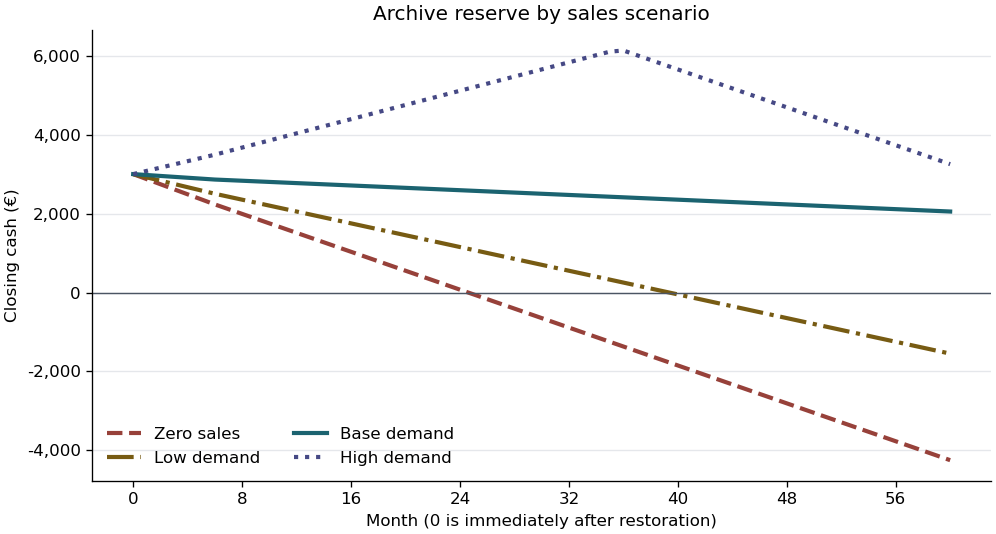

The high-demand case uses all paid slots in month **36**. Hosting and upkeep then draw on the remaining reserve.

In [6]:
# Use line patterns as well as color so that the four cases can be distinguished.
figure, axis = plt.subplots(figsize=(8.3, 4.45), layout="constrained")
line_styles = [
    ("#97413a", "--"),
    ("#775b13", "-."),
    ("#1b6370", "-"),
    ("#464985", ":"),
]
for (name, cash), (color, pattern) in zip(balances.items(), line_styles):
    axis.plot(range(inputs.months + 1), cash, label=name,
              linewidth=2.5, color=color, linestyle=pattern)

# Mark zero cash and keep the units visible without interpreting interim balances as daily cash.
axis.axhline(0, color="#4b5563", linewidth=0.85)
axis.set(
    title="Archive reserve by sales scenario",
    xlabel="Month (0 is immediately after restoration)",
    ylabel="Closing cash (€)",
)
axis.xaxis.set_major_locator(MaxNLocator(integer=True))
axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
axis.grid(axis="y", color="#e5e7eb", linewidth=0.8)
axis.spines[["top", "right"]].set_visible(False)
axis.legend(loc="lower left", frameon=False, ncol=2)
show_figure(figure)

# Identify the high-demand cap month from the plotted scenario.
high_case = next(row for row in sales_rows if row["Scenario"] == "High demand")
if isinstance(high_case["Paid cap reached"], int):
    display(Markdown(
        f"The high-demand case uses all paid slots in month **{high_case['Paid cap reached']}**. "
        "Hosting and upkeep then draw on the remaining reserve."
    ))

## 7. Measure the zero-sales runway

First model zero paid sales from day one. Then allow base demand for the configured opening period and stop sales entirely to see how much time the resulting reserve buys. Free claims still follow the agreed budget in both cases. A month counts as funded when all bills for that month are covered. If there is money left at the end of the forecast, extend the calculation using the same monthly bills and no remaining claims.

In [7]:
def runway(a, cash):
    # Use the first uncovered month even if a later balance would recover.
    gap_month = first_cash_shortfall(cash)
    if gap_month is not None:
        return max(0, gap_month - 1), gap_month, -cash[gap_month]

    # Once all claims are complete, only recurring costs draw down the reserve.
    fixed = monthly_fixed_cost(a)
    if fixed == ZERO:
        return None, None, ZERO

    extra_months = int(cash[-1] // fixed)
    remaining_cash = cash[-1] - extra_months * fixed
    full_months = a.months + extra_months
    return full_months, full_months + 1, fixed - remaining_cash


if type(sales_stop_month) is not int or not 0 <= sales_stop_month <= inputs.months:
    raise ValueError("The chosen sales stop month must be a whole month inside the forecast.")

# Generate a second ledger with no sales after the cutoff.
cutoff_demand = (
    [scenarios["Base demand"]] * sales_stop_month
    + [0] * (inputs.months - sales_stop_month)
)
cutoff_ledger = simulate_sales(inputs, cutoff_demand)
cutoff_cash = balances_with_launch(inputs, cutoff_ledger)
runway_cases = [
    ("No sales from launch", 0, balances["Zero sales"]),
    ("Base demand, then no sales", sales_stop_month, cutoff_cash),
]

runway_rows = []
for label, stop, cash in runway_cases:
    # Count complete months after sales stop and show the first uncovered amount.
    funded_months, gap_month, gap = runway(inputs, cash)
    after_stop = "No finite limit" if funded_months is None else max(0, funded_months - stop)
    if gap_month is not None and gap_month <= stop:
        after_stop = "Already short"
    runway_rows.append({
        "Case": label,
        "Zero sales from": f"Month {stop + 1}",
        "Cash at cutoff": euros(cash[stop]),
        "Full months after cutoff": after_stop,
        "First gap": "—" if gap_month is None else f"Month {gap_month}",
        "Amount short": "—" if gap_month is None else euros(gap),
    })

display(pd.DataFrame(runway_rows).set_index("Case"))

# Show the total cost of the zero-sales case over the modelled horizon.
zero_funded, zero_gap_month, zero_gap = runway(inputs, balances["Zero sales"])
free_delivery = inputs.expected_free_claims * inputs.initial_delivery_cost
display(Markdown(
    f"With no paid licences, the full {inputs.months}-month plan requires "
    f"**{euros(minimum_opening_funding(inputs, balances['Zero sales']))}** at launch. "
    f"That includes {euros(inputs.restoration_cost)} for restoration, "
    f"{euros(monthly_fixed_cost(inputs) * inputs.months)} in recurring bills "
    f"and {euros(free_delivery)} for initial delivery to free claimants."
))

,Zero sales from,Cash at cutoff,Full months after cutoff,First gap,Amount short
Case,,,,,
No sales from launch,Month 1,"€3,000.00",24,Month 25,€48.00
"Base demand, then no sales",Month 13,"€2,772.00",23,Month 36,€108.00


With no paid licences, the full 60-month plan requires **€8,748.00** at launch. That includes €1,500.00 for restoration, €7,200.00 in recurring bills and €48.00 for initial delivery to free claimants.

## 8. Calculate the sales needed to fund preservation

Divide the cost to be funded by the archive contribution per sale and round up to a whole licence. Monthly break-even applies once the free claims have cleared. The full-period thresholds include restoration and claim delivery. The threshold after opening funding measures the total amount that sales must cover. Section 5 still determines whether those sales arrive in time.

In [8]:
def licences_to_cover(cost, contribution):
    # Return the smallest integer count that covers the cost with a positive margin.
    if cost <= ZERO:
        return 0
    if contribution <= ZERO:
        return None
    return int((cost / contribution).to_integral_value(rounding=ROUND_CEILING))


def licence_count(count):
    # A zero or negative contribution cannot cover a remaining positive bill.
    return "No finite count" if count is None else f"{count:,}"


# Add all preservation costs outside paid checkout, which is already in the unit margin.
period_cost = (
    inputs.restoration_cost
    + inputs.months * monthly_fixed_cost(inputs)
    + inputs.expected_free_claims * inputs.initial_delivery_cost
)
monthly_break_even = licences_to_cover(monthly_fixed_cost(inputs), contribution_per_sale)
sales_only_break_even = licences_to_cover(period_cost, contribution_per_sale)
funded_break_even = licences_to_cover(period_cost - inputs.opening_funding, contribution_per_sale)
targets = [
    ("One recurring month after free claims", monthly_fixed_cost(inputs), monthly_break_even),
    ("Full period from sales alone", period_cost, sales_only_break_even),
    ("Full period after opening funding", max(ZERO, period_cost - inputs.opening_funding), funded_break_even),
]

display(pd.DataFrame([
    {"Funding target": label, "Amount to cover": euros(cost), "Paid licences needed": licence_count(count)}
    for label, cost, count in targets
]).set_index("Funding target"))

# Compare the sellout contribution with the cost if there were no opening funding.
sellout_contribution = paid_capacity * contribution_per_sale
sales_only_gap = max(ZERO, period_cost - sellout_contribution)
display(Markdown(
    f"Selling all **{paid_capacity:,} paid licences** contributes **{euros(sellout_contribution)}** "
    f"at this price and royalty rate. The full-period gap in the sales-only calculation is "
    f"**{euros(sales_only_gap)}**."
))

,Amount to cover,Paid licences needed
Funding target,,
One recurring month after free claims,€120.00,16
Full period from sales alone,"€8,748.00","1,167"
Full period after opening funding,"€4,248.00",567


Selling all **1,000 paid licences** contributes **€7,500.00** at this price and royalty rate. The full-period gap in the sales-only calculation is **€1,248.00**.

## 9. Vary the price and royalty

The price and royalty both change how much one sale leaves for the archive. Hold fees, costs, the supply cap and opening funding constant, then recalculate the full-period sales threshold at nearby prices and royalty rates. Mark any combination that needs more paid licences than the cap allows. Estimating how those prices would affect demand requires buyer data.

In [9]:
# Test the baseline and nearby values while keeping prices and rates in range.
prices = sorted({
    max(ZERO, inputs.licence_price - Decimal("3.00")),
    inputs.licence_price,
    inputs.licence_price + Decimal("3.00"),
})
royalty_rates = sorted({
    max(ZERO, inputs.royalty_rate - Decimal("0.10")),
    inputs.royalty_rate,
    min(Decimal("1.00"), inputs.royalty_rate + Decimal("0.10")),
})
sales_funding_target = period_cost - inputs.opening_funding
sensitivity_rows = []

for price in prices:
    row = {"Paid licence price": euros(price)}
    for rate in royalty_rates:
        # Reuse the per-sale payout rules so rounding stays consistent across cases.
        alternative = replace(inputs, licence_price=price, royalty_rate=rate)
        _, _, contribution = unit_economics(alternative)
        needed = licences_to_cover(sales_funding_target, contribution)
        value = licence_count(needed)
        if needed is None or needed > paid_capacity:
            value += " *"
        row[f"{rate:.1%} royalty"] = value
    sensitivity_rows.append(row)

display(pd.DataFrame(sensitivity_rows).set_index("Paid licence price"))
display(Markdown(
    f"Each cell gives the paid licences needed after {euros(inputs.opening_funding)} of opening funding. "
    f"An asterisk indicates a threshold outside the **{paid_capacity:,}** available paid slots."
))

,20.0% royalty,30.0% royalty,40.0% royalty
Paid licence price,,,
€9.00,665,774,926
€12.00,489,567,675
€15.00,386,447,531


Each cell gives the paid licences needed after €4,500.00 of opening funding. An asterisk indicates a threshold outside the **1,000** available paid slots.

## 10. Simulate uncertain demand

Draw one sustained monthly demand level for each simulated edition and apply it over the whole forecast. A triangular distribution gives more weight to rates near the assumed most common level and less to the extremes. This tests the effect of uncertainty about an edition's long-run popularity. It keeps costs fixed and allows no separate month-to-month demand changes within a path. The share with a funding gap is conditional on these synthetic inputs.

In [10]:
# Check the sampling inputs before generating reproducible demand paths.
if type(simulation_count) is not int or simulation_count < 1:
    raise ValueError("Use a positive whole number of simulated paths.")
if not 0 <= demand_low <= demand_mode <= demand_high:
    raise ValueError("Set the simulation demand inputs in minimum, mode, maximum order.")

rng = Random(random_seed)
required_funding = []
for _ in range(simulation_count):
    # Sample sustained monthly demand, then use the same cap and monthly cash ledger.
    demand = round(rng.triangular(low=demand_low, high=demand_high, mode=demand_mode))
    simulated = simulate_sales(inputs, [demand] * inputs.months)
    cash = balances_with_launch(inputs, simulated)
    required_funding.append(minimum_opening_funding(inputs, cash))

# Count paths that need more funding than the amount available.
shortfall_count = sum(funding > inputs.opening_funding for funding in required_funding)
median_funding = median(required_funding)
simulation_stats = [
    ("Simulated paths", f"{simulation_count:,}"),
    ("Paths with any cash gap", f"{shortfall_count:,}"),
    ("Share with a cash gap", f"{shortfall_count / simulation_count:.1%}"),
    ("Median opening funding required", euros(median_funding)),
]
display(pd.DataFrame(
    simulation_stats, columns=["Simulation result", "Value"],
).set_index("Simulation result"))
display(Markdown(
    f"Demand draws use **{demand_low} / {demand_mode} / {demand_high}** "
    f"buyers per month as minimum, mode and maximum. The random seed is **{random_seed}**."
))

,Value
Simulation result,
Simulated paths,"2,000"
Paths with any cash gap,437
Share with a cash gap,21.9%
Median opening funding required,"€2,448.00"


Demand draws use **0 / 14 / 28** buyers per month as minimum, mode and maximum. The random seed is **42**.

## 11. See how funding needs are distributed

The bars count simulated paths at different levels of required opening funding. The dashed line marks the opening funding available. A path needs more funding if its required amount lies to the right of the line. The table above counts this using each path's exact amount because one bar can span the threshold.

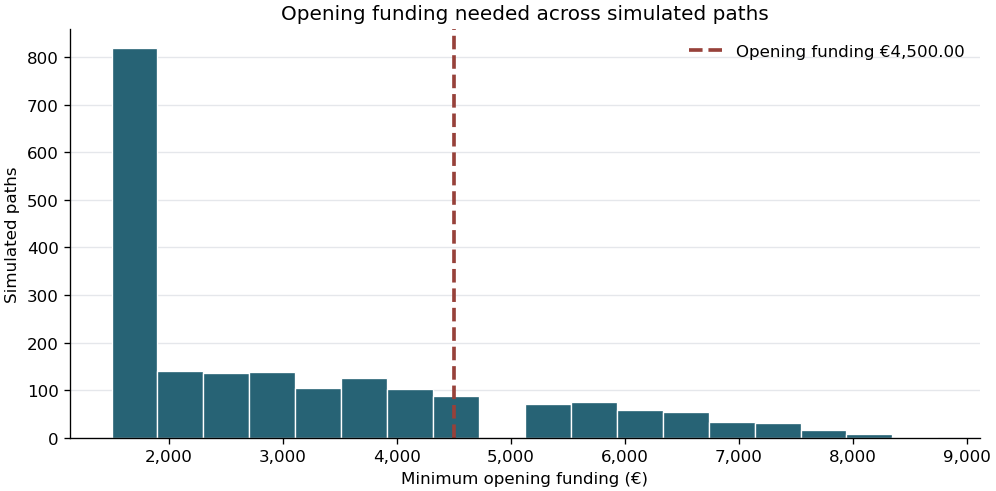

In [11]:
# Show the distribution of minimum funding, measured before paying for restoration.
figure, axis = plt.subplots(figsize=(8.3, 4.1), layout="constrained")
axis.hist([float(amount) for amount in required_funding], bins=18,
          color="#276375", edgecolor="white", linewidth=0.8)
axis.axvline(float(inputs.opening_funding), color="#97413a", linestyle="--",
             linewidth=2.2, label=f"Opening funding {euros(inputs.opening_funding)}")
axis.set(
    title="Opening funding needed across simulated paths",
    xlabel="Minimum opening funding (€)",
    ylabel="Simulated paths",
)
axis.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
axis.yaxis.set_major_locator(MaxNLocator(integer=True))
axis.set_axisbelow(True)
axis.grid(axis="y", color="#e5e7eb", linewidth=0.8)
axis.spines[["top", "right"]].set_visible(False)
axis.legend(loc="upper right", frameon=False)
show_figure(figure)

## Model boundaries

The rights holder authorizes licence issuance. The preservation agency maintains the independent backup archive. Upkeep includes storage checks, administration and later downloads within the assumed service capacity. Initial delivery is charged once for each paid or free issue. Restoration and operating costs stay constant in nominal euros over the forecast.

The model starts at launch with no previous token issues. It uses hypothetical price, fee, demand and cost figures. Taxes, refunds, price changes and temporary outage costs are outside the cash ledger. The testnet token would record an entitlement according to the project's licence terms. This notebook models that entitlement's finances and uses no blockchain transactions or game files.

Sections 12–15 extend the baseline with explicit cost growth, refunds, recovery expenses and intervention rules. The earlier constant-cost results remain the reference case.

## 12. Stress the cost and recovery assumptions

All new values are hypothetical sensitivity choices, rather than measured supplier costs or loss probabilities.

| Input | Example and reasoning |
| --- | --- |
| Monthly cost multiplier | 1.5 makes both hosting and upkeep 50% more expensive, testing a material pricing error. |
| Annual bill growth | 5% at months 13, 25, 37 and 49 tests loss of purchasing power while the sale price stays fixed. It is an example, not an inflation forecast. |
| Restoration or migration incident | EUR 600 in month 24 tests an expense after launch. It funds recovery work within the existing architecture. |
| Recovery support | 10 cases at EUR 25 in month 18 costs EUR 250. This buys staff time, not automatic wallet replacement. |
| Refunds | Five full EUR 12 refunds in month 12 cost EUR 60. Fees and royalties already paid are conservatively unrecovered, and minted capacity stays occupied. |
| Sales interruption | 14 buyers monthly for 12 months, then zero, tests loss of demand or issuer availability. |
| Intervention reserve | Six coming months of scheduled bills and claims plus EUR 600 for orderly exit. It triggers a review before cash exhaustion. |

The scenarios assume no extra cash from transfers, DLC, token appreciation or uncommitted grants. Refunded orders must already have been issued. The ledger continues after a negative cash balance to measure the unfunded requirement. It does not authorise unfunded spending.

In [12]:
@dataclass(frozen=True)
class StressCosts:
    # Bill growth takes effect on each launch anniversary.
    monthly_multiplier: Decimal = Decimal("1.00")
    annual_growth: Decimal = Decimal("0.00")
    incident_month: int = 24
    incident_cost: Decimal = Decimal("0.00")
    recovery_month: int = 18
    recovery_cases: int = 0
    cost_per_recovery: Decimal = Decimal("25.00")
    refund_month: int = 12
    refund_count: int = 0


def recurring_bill(a, costs, month):
    # Compound on annual anniversaries, rounding the actual monthly bill to cents.
    years = (month - 1) // 12
    return to_cents(monthly_fixed_cost(a) * costs.monthly_multiplier
                    * (Decimal("1") + costs.annual_growth) ** years)


def simulate_stress(a, demand, costs):
    # Reuse the original issuance, royalty and delivery accounting.
    validate_assumptions(a)
    if costs.monthly_multiplier < 0 or costs.annual_growth < 0:
        raise ValueError("Cost multiplier and annual growth must be nonnegative.")
    for month in (costs.incident_month, costs.recovery_month, costs.refund_month):
        if type(month) is not int or not 1 <= month <= a.months:
            raise ValueError("Every event month must fit in the forecast.")
    for count in (costs.recovery_cases, costs.refund_count):
        if type(count) is not int or count < 0:
            raise ValueError("Recovery and refund counts must be nonnegative integers.")
    for amount in (costs.incident_cost, costs.cost_per_recovery):
        if amount < 0 or amount != to_cents(amount):
            raise ValueError("Event costs must be nonnegative cent amounts.")
    rows = simulate_sales(a, demand)
    cash = a.opening_funding - a.restoration_cost
    issued = 0
    for row in rows:
        month = row["month"]
        issued += row["paid_licences"]
        refunds = costs.refund_count if month == costs.refund_month else 0
        if refunds > issued:
            raise ValueError("Refunds cannot exceed paid issues to date.")
        row["fixed_cost"] = recurring_bill(a, costs, month)
        row["incident_cost"] = costs.incident_cost if month == costs.incident_month else ZERO
        row["recovery_cost"] = (costs.recovery_cases * costs.cost_per_recovery
                                if month == costs.recovery_month else ZERO)
        row["refund_cost"] = refunds * a.licence_price
        row["cash_change"] = (
            row["gross_sales"] - row["royalties"] - row["checkout_fees"]
            - row["paid_delivery"] - row["claim_delivery"] - row["fixed_cost"]
            - row["incident_cost"] - row["recovery_cost"] - row["refund_cost"]
        )
        cash += row["cash_change"]
        row["cash_balance"] = cash
    return rows


# Each named case changes explicit inputs from the same original baseline.
steady_demand = [base_monthly_demand] * inputs.months
stress_cases = {
    "Baseline": (steady_demand, StressCosts()),
    "Higher monthly bills": (steady_demand, StressCosts(monthly_multiplier=Decimal("1.50"))),
    "Annual bill growth": (steady_demand, StressCosts(annual_growth=Decimal("0.05"))),
    "Recovery and refunds": (steady_demand, StressCosts(
        incident_cost=Decimal("600.00"), recovery_cases=10, refund_count=5)),
    "Sales stop": (cutoff_demand, StressCosts()),
    "Combined stress": (cutoff_demand, StressCosts(
        monthly_multiplier=Decimal("1.50"), annual_growth=Decimal("0.05"),
        incident_cost=Decimal("600.00"), recovery_cases=10, refund_count=5)),
}
stress_ledgers = {
    name: simulate_stress(inputs, demand, costs)
    for name, (demand, costs) in stress_cases.items()
}

# Neutral stress inputs must reproduce every baseline balance exactly.
assert [r["cash_balance"] for r in stress_ledgers["Baseline"]] == [
    r["cash_balance"] for r in base_ledger
]
assert recurring_bill(inputs, StressCosts(annual_growth=Decimal("0.05")), 13) == Decimal("126.00")
assert sum(r["refund_cost"] for r in stress_ledgers["Recovery and refunds"]) == Decimal("60.00")
assert stress_ledgers["Recovery and refunds"][-1]["paid_slots_left"] == base_ledger[-1]["paid_slots_left"]


## 13. Compare cash gaps and required funding

Minimum opening funding covers the deepest cash deficit anywhere in the forecast, including restoration at launch. Additional funding is the amount beyond the existing EUR 4,500. A positive final balance can still follow an earlier gap, so the table also reports the first unpaid month. Costs and refunds are cash outflows. No refund, recovery or transfer reopens a minted slot.

,Closing cash,First cash gap,Opening funding needed,Additional funding,Paid issues
Scenario,,,,,
Baseline,"€2,052.00",None in horizon,"€2,448.00",€0.00,840
Higher monthly bills,"-€1,548.00",Month 40,"€6,048.00","€1,548.00",840
Annual bill growth,"€1,295.04",None in horizon,"€3,204.96",€0.00,840
Recovery and refunds,"€1,142.00",None in horizon,"€3,358.00",€0.00,840
Sales stop,"-€2,988.00",Month 36,"€7,488.00","€2,988.00",168
Combined stress,"-€8,633.32",Month 22,"€13,133.32","€8,633.32",168


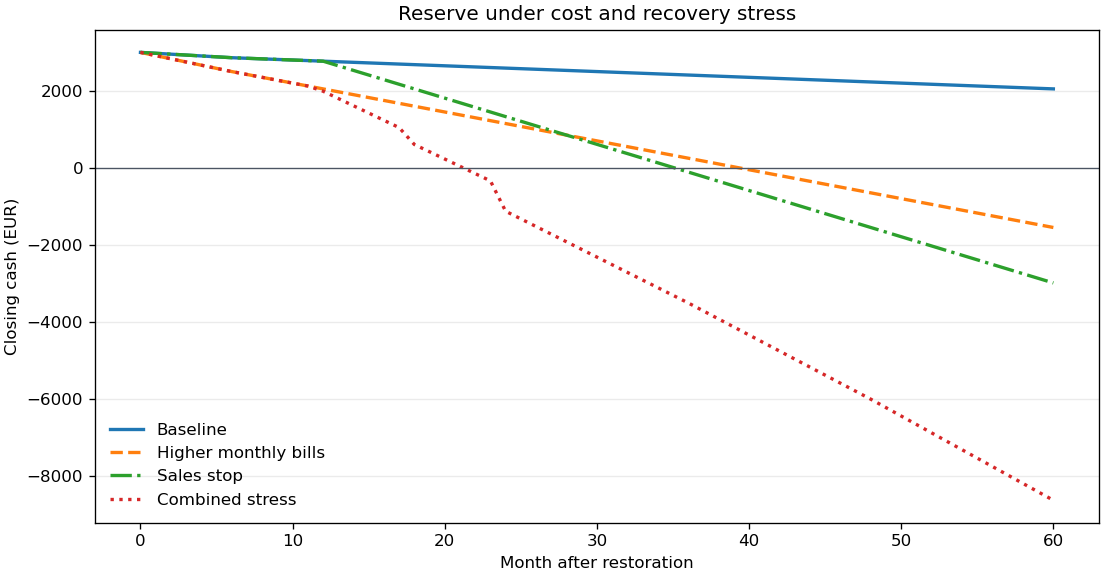

In [13]:
stress_summary = []
for name, rows in stress_ledgers.items():
    # Independently reconcile each scenario using its individual income and expense lines.
    inflows = sum(r["gross_sales"] for r in rows)
    outflows = sum(
        r["royalties"] + r["checkout_fees"] + r["paid_delivery"] + r["claim_delivery"]
        + r["fixed_cost"] + r["incident_cost"] + r["recovery_cost"] + r["refund_cost"]
        for r in rows
    )
    assert rows[-1]["cash_balance"] == cash_at_launch + inflows - outflows
    cash = balances_with_launch(inputs, rows)
    needed = max(inputs.restoration_cost, minimum_opening_funding(inputs, cash))
    gap = first_cash_shortfall(cash)
    stress_summary.append({
        "Scenario": name,
        "Closing cash": euros(cash[-1]),
        "First cash gap": "None in horizon" if gap is None else f"Month {gap}",
        "Opening funding needed": euros(needed),
        "Additional funding": euros(max(ZERO, needed - inputs.opening_funding)),
        "Paid issues": sum(r["paid_licences"] for r in rows),
    })
display(pd.DataFrame(stress_summary).set_index("Scenario"))

# Show timing with accessible line patterns and values in the table above.
figure, axis = plt.subplots(figsize=(9.2, 4.8), layout="constrained")
for name, pattern in (("Baseline", "-"), ("Higher monthly bills", "--"),
                      ("Sales stop", "-."), ("Combined stress", ":")):
    axis.plot(range(inputs.months + 1),
              balances_with_launch(inputs, stress_ledgers[name]),
              label=name, linestyle=pattern, linewidth=2)
axis.axhline(0, color="#4b5563", linewidth=0.8)
axis.set(title="Reserve under cost and recovery stress",
         xlabel="Month after restoration", ylabel="Closing cash (EUR)")
axis.grid(axis="y", alpha=0.25)
axis.legend(frameon=False)
show_figure(figure)


## 14. Set a warning floor before cash runs out

At each month end, earmark the next six months of recurring costs and free-claim delivery plus the EUR 600 exit allowance. The floor excludes future sales and uncommitted funding. At the forecast end the six-month look-ahead still includes operating bills, avoiding an artificial drop to zero.

These are proposed operating thresholds. A floor breach triggers partner review, a funding decision and holder communication. Fund a defined service term or organise permitted final downloads and an orderly exit. The forecast is an illustration of when to intervene, not a guarantee of perpetual access.

In [14]:
warning_months = 6
exit_allowance = Decimal("600.00")


def warning_floor(a, costs, month):
    # Look beyond the chart horizon for recurring bills, while claims use their actual schedule.
    claims = free_claim_schedule(a)
    bills = sum((recurring_bill(a, costs, future)
                 for future in range(month + 1, month + warning_months + 1)), ZERO)
    claim_cost = sum(claims[month:month + warning_months]) * a.initial_delivery_cost
    return bills + claim_cost + exit_allowance


warning_rows = []
for name, rows in stress_ledgers.items():
    costs = stress_cases[name][1]
    cash = balances_with_launch(inputs, rows)
    warning = next((month for month, balance in enumerate(cash)
                    if balance <= warning_floor(inputs, costs, month)), None)
    warning_rows.append({
        "Scenario": name,
        "First review trigger": "None in horizon" if warning is None else f"Month {warning}",
        "Cash at trigger": "—" if warning is None else euros(cash[warning]),
        "Required floor": "—" if warning is None else euros(warning_floor(inputs, costs, warning)),
    })
display(pd.DataFrame(warning_rows).set_index("Scenario"))

# The zero-growth baseline floor is EUR 1,320 once free claims have ended.
assert warning_floor(inputs, StressCosts(), 6) == Decimal("1320.00")


,First review trigger,Cash at trigger,Required floor
Scenario,,,
Baseline,None in horizon,—,—
Higher monthly bills,Month 17,"€1,677.00","€1,680.00"
Annual bill growth,Month 56,"€1,458.48","€1,489.74"
Recovery and refunds,Month 49,"€1,307.00","€1,320.00"
Sales stop,Month 25,"€1,212.00","€1,320.00"
Combined stress,Month 14,"€1,614.00","€1,734.00"


## 15. Price a funded service term

For the same monthly buyers and issue cap, find the lowest whole-cent price that keeps every month funded in the 60-month plan. Primary royalties, fixed and percentage processing fees, delivery, refunds and event costs retain their scenario definitions. This price funds operating cash through the horizon. The separate six-month intervention floor remains an additional prudence policy.

The calculation assumes demand does not change when the price changes. Buyer research is required before treating the result as achievable pricing. If zero demand cannot cover costs, the output says external funding is required.

In [15]:
def price_for_funded_term(a, demand, costs):
    # Search whole cents so the quoted price agrees with checkout rounding.
    def funded(cents):
        alternative = replace(a, licence_price=Decimal(cents) / 100)
        rows = simulate_stress(alternative, demand, costs)
        return min(balances_with_launch(alternative, rows)) >= ZERO

    if funded(0):
        return ZERO
    if not any(demand):
        return None
    lower, upper = 0, 100
    while not funded(upper):
        upper *= 2
        if upper > 100_000_000:
            return None
    while lower + 1 < upper:
        middle = (lower + upper) // 2
        if funded(middle):
            upper = middle
        else:
            lower = middle
    return Decimal(upper) / 100


price_rows = []
for name, (demand, costs) in stress_cases.items():
    price = price_for_funded_term(inputs, demand, costs)
    if price is not None:
        # Verify the candidate funds each month and the preceding cent fails.
        alternative = replace(inputs, licence_price=price)
        assert min(balances_with_launch(
            alternative, simulate_stress(alternative, demand, costs))) >= ZERO
        if price > ZERO:
            previous = replace(inputs, licence_price=price - CENT)
            assert min(balances_with_launch(
                previous, simulate_stress(previous, demand, costs))) < ZERO
    price_rows.append({
        "Scenario": name,
        "Minimum price for 60 months": "External funding required" if price is None else euros(price),
    })
display(pd.DataFrame(price_rows).set_index("Scenario"))
display(Markdown(
    "Recovery support costs pay for case handling. The current contract cannot cancel a lost "
    "token or move it without its signing key. The [recovery policy](docs/ENTITLEMENT-AND-RECOVERY.md) "
    "documents supported actions, protected capacity and the conditions for any future migration."
))


,Minimum price for 60 months
Scenario,
Baseline,€8.36
Higher monthly bills,€14.76
Annual bill growth,€9.70
Recovery and refunds,€9.96
Sales stop,€38.56
Combined stress,€92.27


Recovery support costs pay for case handling. The current contract cannot cancel a lost token or move it without its signing key. The [recovery policy](docs/ENTITLEMENT-AND-RECOVERY.md) documents supported actions, protected capacity and the conditions for any future migration.